# PoliceWear quick start

The data live in ../data/: five tables plus one gzipped CSV per participant for PPG and for the accelerometer.
Times are given as a study day (1 = the participant's earliest record) and a clock time (KST); there are no calendar dates.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, os
REL = os.path.join('..', 'data', '')
rd = lambda f: pd.read_csv(REL + f, encoding='utf-8-sig')
P, W, E, D, A = (rd(f) for f in ['participants.csv', 'watch_collections.csv', 'sleep_episodes.csv', 'sleep_daily.csv', 'activity_daily.csv'])
print({'participants': len(P), 'watch recordings': len(W), 'sleep episodes': len(E), 'sleep nights': len(D), 'step days': len(A)})
P.head()

{'participants': 328, 'watch recordings': 77528, 'sleep episodes': 5246, 'sleep nights': 3707, 'step days': 4920}


,pid,wave,sex,age_group,bmi,group,work_type,O_sum,C_sum,E_sum,A_sum,N_sum,brs_score,pss,phq9,gad7,fatigue
0,P1063,1,male,30-39,24.5,healthy,day,17,21,20,22,17,3.17,10,1,0,27
1,P1077,1,female,30-39,25.5,healthy,day,21,23,17,24,17,4.00,15,5,3,31
2,P1145,2,female,30-39,22.5,stress,day,13,19,16,23,19,3.67,17,3,2,27
3,P1149,1,male,30-39,29.0,stress,shift,18,17,11,19,14,3.17,18,6,0,31
4,P1155,1,male,50+,28.1,depression,day,22,22,14,16,17,2.67,19,12,5,19


## What each participant has

In [2]:
per = (W.groupby('pid').agg(wave=('wave', 'first'), recordings=('day', 'size'), days=('day', 'nunique'), ratings=('ema_stress', 'count'))
         .join(E.groupby('pid').size().rename('sleep_episodes'))
         .join(A.groupby('pid').size().rename('step_days')))
per.describe().round(1)

,wave,recordings,days,ratings,sleep_episodes,step_days
count,328.0,328.0,328.0,328.0,289.0,230.0
mean,1.5,236.4,15.5,94.1,18.2,21.4
std,0.5,117.1,7.1,52.7,12.2,13.9
min,1.0,38.0,4.0,10.0,1.0,1.0
25%,1.0,143.8,9.0,45.0,9.0,10.0
50%,1.0,207.0,16.0,90.5,15.0,17.0
75%,2.0,327.5,20.0,136.2,25.0,30.0
max,2.0,710.0,39.0,289.0,70.0,59.0


## One recording: raw PPG and accelerometer with its stress rating

Each recording is 64 s at 25 Hz. `t_s` is seconds since the recording trigger; rows are ordered by recording and time.

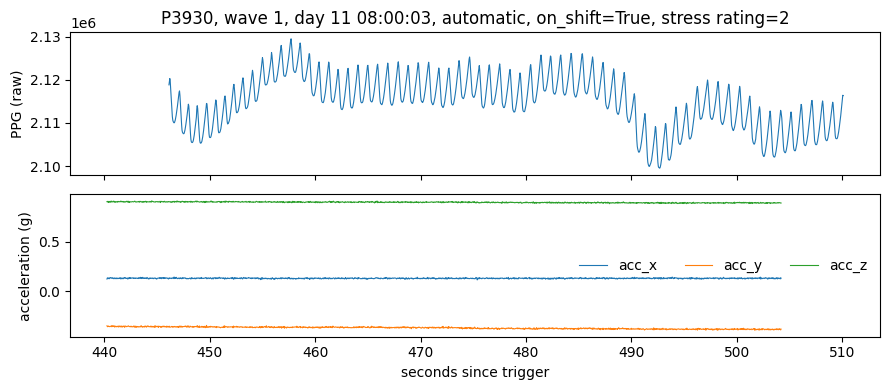

In [3]:
rec = W[(W.pid == 'P3930') & (W.day == 11) & (W.time_kst == '08:00:03')].iloc[0]   # a clean on-duty recording with a stress rating; change the key to browse others
ppg = pd.read_csv(f"{REL}ppg/wave{rec.wave}/{rec.pid}.csv.gz", dtype={'time_kst': str})
acc = pd.read_csv(f"{REL}acc/wave{rec.wave}/{rec.pid}.csv.gz", dtype={'time_kst': str})
key = (ppg.day == rec.day) & (ppg.time_kst == rec.time_kst); keya = (acc.day == rec.day) & (acc.time_kst == rec.time_kst)
fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
ax[0].plot(ppg.t_s[key], ppg.ppg[key], lw=0.8); ax[0].set_ylabel('PPG (raw)')
ax[0].set_title(f"{rec.pid}, wave {rec.wave}, day {rec.day} {rec.time_kst}, {rec.collection_type}, on_shift={rec.on_shift}, stress rating={int(rec.ema_stress)}")
for c in ['acc_x', 'acc_y', 'acc_z']: ax[1].plot(acc.t_s[keya], acc[c][keya] / 4096, lw=0.8, label=c)
ax[1].set_ylabel('acceleration (g)'); ax[1].set_xlabel('seconds since trigger'); ax[1].legend(ncol=3, frameon=False)
plt.tight_layout()

## Heart rate from the band-passed signal (simple example)

66 beats, heart rate 62 bpm


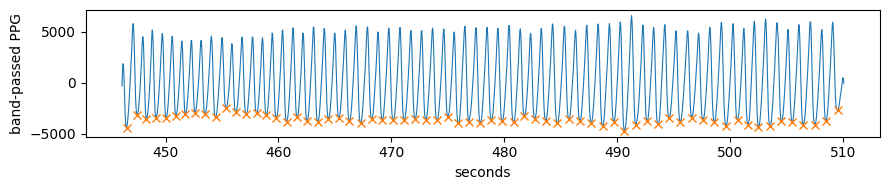

In [4]:
from scipy.signal import butter, sosfiltfilt, find_peaks
x = ppg.ppg[key].to_numpy(float); fs = 25.0
y = sosfiltfilt(butter(3, [0.5, 4], btype='band', fs=fs, output='sos'), x - x.mean())
troughs, _ = find_peaks(-y / np.median(np.abs(y)), distance=int(0.33 * fs), prominence=1.0)   # green PPG dips with each pulse
ibi = np.diff(troughs) / fs; ibi = ibi[(ibi > 0.33) & (ibi < 1.5)]
print(f"{len(ibi)} beats, heart rate {60 / np.median(ibi):.0f} bpm")
plt.figure(figsize=(9, 2)); plt.plot(ppg.t_s[key], y, lw=0.8); plt.plot(ppg.t_s[key].to_numpy()[troughs], y[troughs], 'x'); plt.xlabel('seconds'); plt.ylabel('band-passed PPG'); plt.tight_layout()

## Stress ratings by recruitment group and work type

In [5]:
m = W.dropna(subset=['ema_stress']).merge(P[['pid', 'group', 'work_type']], on='pid')
pd.crosstab([m.group, m.work_type], m.ema_stress.astype(int), normalize='index').round(2)

ema_stress               0     1     2     3
group      work_type                        
depression day        0.19  0.41  0.25  0.14
           duty       0.32  0.37  0.23  0.07
           shift      0.27  0.40  0.24  0.09
healthy    day        0.57  0.35  0.07  0.01
           duty       0.64  0.30  0.05  0.01
           shift      0.67  0.26  0.06  0.01
stress     day        0.36  0.40  0.17  0.07
           duty       0.40  0.26  0.14  0.19
           shift      0.46  0.36  0.14  0.05